# Faster R-CNN 베이스라인 (ResNet-50-FPN V2)

torchvision `fasterrcnn_resnet50_fpn_v2`를 YOLO 후보(YOLO11m·YOLO26m)와 **같은 라벨·같은 분할·같은
지표**로 학습·평가한다. 핵심 질문은 2-stage 검출기가 bbox 정밀도(mAP75-95)에서 YOLO보다 나은가이다.

- 이 노트북 한 파일 안에서 끝낸다. 프로젝트의 python 파일(`src/`, `data_process/`, `models/` 등)은
  import하지 않고, 필요한 기능은 아래 함수로 다시 구현한다.
- 라벨: 원본 JSON + 통합 보정 기록(`data/processed/corrections.csv`)의 v1 기록을 노트북 안에서 적용한다.
  라벨 txt·분할 목록·`data.yaml` 파일은 만들지 않는다.
- 평가: AP 계산은 ultralytics 검증과 같은 방식(클래스가 같은 정답과만 짝, 101점 보간)으로 직접 구현한다.
- 결과: `runs/<exp>/results/`에 YOLO `evaluate_fold`와 같은 열의 `*_summary.csv`, `*_per_class.csv`를
  저장하므로 YOLO 결과와 한 표로 모을 수 있다.

순서: 1 설정 → 2 라벨 → 3 분할 → 4 데이터셋 → 5 모델 → 6 평가 지표 → 7 예측·평가 → 8 학습 루프
→ 9 동작 확인 → 10 본 학습 → 11 요약 → 12 학습 곡선 → 13 혼동행렬 → 14 실패 사례 → 15 제출

## 1. 설정

하이퍼파라미터는 `FASTER_RCNN_REQUIREMENTS.md` 4절에서 확정한 값이다. 코드에 고정하지 않고 `CFG`로
함수에 넘기며, 실행한 설정 전체를 run 폴더의 `config.json`에 남긴다.
Colab에서는 `runs_dir`를 Drive 아래(예: `/content/drive/MyDrive/pill-bbox/runs`)로 바꾼다.

In [22]:
import os

# MPS에 없는 연산이 있으면 CPU로 넘긴다. torch import 전에 정해야 한다.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import contextlib
import json
import math
import platform
import random
import sys
import time
import warnings
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm


def find_project_root(start: Path) -> Path:
    """start에서 위로 올라가며 pyproject.toml이 있는 폴더를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").is_file():
            return path
    raise FileNotFoundError(f"{start} 위에서 pyproject.toml을 찾지 못했습니다.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_IMG_DIR = RAW_DIR / "train_images"
TEST_IMG_DIR = RAW_DIR / "test_images"
ANN_DIR = RAW_DIR / "train_annotations"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

CFG = {
    "exp": "frcnn_base",
    "runs_dir": str(PROJECT_ROOT / "runs"),
    # 데이터
    "label_version": "v1",
    "split_unit": "combo",
    "fix_rare": False,  # True면 희귀 약이 든 조합을 모든 fold에서 train에 고정(combofix 분할)
    "n_folds": 5,
    "folds": [0, 1, 2, 3, 4],
    "fraction": 1.0,  # train 사진 중 이 비율만 사용(동작 확인용)
    "seed": 42,
    # 모델
    "pretrained": "coco",  # coco: COCO_V1 전체 / imagenet: 백본만 ImageNet
    "trainable_backbone_layers": 5,  # 5 = 전체 파인튜닝
    "min_size": 800,
    "max_size": 1333,
    # 학습
    "epochs": 100,
    "batch": 4,
    "optimizer": "SGD",
    "lr0": 0.001,
    "momentum": 0.9,
    "weight_decay": 1e-4,
    "warmup_epochs": 1.0,  # 이 기간 동안 lr을 lr0 × warmup_factor에서 lr0까지 선형으로 올림
    "warmup_factor": 0.001,
    "cos_lr": True,  # True: warmup 뒤 cosine으로 줄임 / False: warmup 뒤 lr0 고정
    "lrf": 0.01,  # cosine 끝의 lr = lr0 × lrf (ultralytics lrf 기본값과 같음)
    "hflip_p": 0.0,  # 증강은 나중에. 0이면 증강 없음
    "amp": True,  # cuda에서만 켜진다
    "patience": 10,  # val mAP75-95가 이 epoch 수만큼 좋아지지 않으면 멈춤
    "workers": 0 if sys.platform == "darwin" else 2,  # mac 노트북은 spawn 문제로 0
    # 평가: YOLO evaluate_fold와 같은 조건
    "conf": 0.001,  # torchvision 기본 box_score_thresh=0.05 대신
    "max_det": 300,  # torchvision 기본 box_detections_per_img=100 대신
    "nms_iou": 0.5,  # torchvision 기본 box_nms_thresh (클래스별 NMS)
    "eval_batch": 4,
}

In [23]:
def get_device() -> str:
    """CUDA > MPS > CPU 순서로 장치를 고른다(src.config.get_device와 같은 규칙)."""
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def sync(device: str) -> None:
    """시간을 잴 때 비동기로 도는 GPU 연산이 끝날 때까지 기다린다."""
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def seed_everything(seed: int) -> None:
    """python·numpy·torch 난수를 고정한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def set_korean_font() -> None:
    """설치된 한글 글꼴이 있으면 matplotlib 기본 글꼴로 쓴다."""
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["AppleGothic", "NanumGothic", "Malgun Gothic", "Noto Sans CJK KR"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            break
    plt.rcParams["axes.unicode_minus"] = False


DEVICE = get_device()
set_korean_font()
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"device: {DEVICE}, torch {torch.__version__}, torchvision {torchvision.__version__}")

PROJECT_ROOT: /Users/yundong-ug/dev/pillbbox
device: mps, torch 2.14.1, torchvision 0.29.1


## 2. 라벨 (v1)

원본 JSON을 bbox 한 행 표로 읽고, 통합 보정 기록에서 v1 기록(`kwon_added`, `kwon_fixed`,
`jjam_capsule`)만 적용한다. 보정은 "지금 박스가 기록의 이전 좌표와 같을 때만" 적용하고, 하나라도
적용되지 않으면 멈춘다. 이미지 크기는 JSON 값 대신 실제 파일 헤더 값을 쓴다.
기대값: 라벨 771개, 클래스 56개, 이미지 밖·크기 0 이하·같은 사진 같은 약 중복 0.

In [24]:
BBOX_COLS = ["x", "y", "w", "h"]
LABEL_PREFIXES = {
    "raw": (),
    "v1": ("kwon_added:", "kwon_fixed:", "jjam_capsule:"),
}
STAGES = ["추가", "위치 수정"]


def as_objects(value: object) -> list[dict]:
    """JSON의 단일 객체와 객체 목록을 같은 형태로 다룬다."""
    return [value] if isinstance(value, dict) else list(value)


def load_annotations(ann_dir: Path) -> pd.DataFrame:
    """annotation JSON을 모두 읽어 원본 bbox당 한 행인 표를 만든다.

    이미지 정보는 JSON 안의 image_id로 연결하고, (source_json, annotation_id)가 라벨 식별자다.
    """
    rows = []
    for json_path in sorted(ann_dir.rglob("*.json")):
        data = json.loads(json_path.read_text(encoding="utf-8-sig"))
        images = {img["id"]: img for img in as_objects(data["images"])}
        for ann in as_objects(data["annotations"]):
            img = images[ann["image_id"]]
            x, y, w, h = (float(v) for v in ann["bbox"])
            rows.append(
                {
                    "file_name": img["file_name"],
                    "source_json": json_path.relative_to(ann_dir).as_posix(),
                    "annotation_id": int(ann["id"]),
                    "category_id": int(ann["category_id"]),
                    "dl_name": img.get("dl_name"),
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "has_segmentation": bool(ann.get("segmentation")),
                }
            )
    return pd.DataFrame(rows)


def read_image_sizes(img_dir: Path) -> pd.DataFrame:
    """이미지 헤더만 읽어 file_name, width, height 표를 만든다."""
    rows = []
    for path in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in {".png", ".jpg"}):
        with Image.open(path) as img:
            rows.append({"file_name": path.name, "width": img.width, "height": img.height})
    return pd.DataFrame(rows)


def parse_bbox(text: str) -> tuple[int, int, int, int]:
    """보정 기록의 "[x, y, w, h]" 문자열을 정수 튜플로 바꾼다."""
    return tuple(int(round(float(v))) for v in text.strip("[]").split(","))


def apply_corrections(ann: pd.DataFrame, corrections: pd.DataFrame, version: str) -> pd.DataFrame:
    """라벨 버전의 보정 기록을 추가 → 위치 수정 순서로 적용한 복사본을 반환한다.

    기록이 하나라도 적용되지 않으면(미검수, 대상 없음, 현재 bbox ≠ old_bbox 등) 오류를 낸다.
    """
    df = ann.copy()
    df["label_origin"] = "원본"
    selected = corrections[corrections["correction_id"].str.startswith(LABEL_PREFIXES[version])]
    failed = []
    for stage in STAGES:
        for _, rec in selected[selected["stage"] == stage].iterrows():
            x, y, w, h = parse_bbox(rec["new_bbox"])
            if rec["reviewed"] is not True and str(rec["reviewed"]) != "True":
                failed.append((rec["correction_id"], "미검수"))
                continue
            if stage == "추가":
                same = (df["file_name"] == rec["file_name"]) & (
                    df["category_id"] == rec["category_id"]
                )
                if same.any():
                    failed.append((rec["correction_id"], "같은 사진에 같은 약 라벨이 이미 있음"))
                    continue
                same_drug = df.loc[df["category_id"] == rec["category_id"], "dl_name"]
                new_row = {
                    "file_name": rec["file_name"],
                    "source_json": None,
                    "annotation_id": int(rec["annotation_id"]),
                    "category_id": int(rec["category_id"]),
                    "dl_name": same_drug.iloc[0] if len(same_drug) else None,
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "has_segmentation": False,
                    "label_origin": "추가",
                }
                df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
                continue
            target = (df["source_json"] == rec["source_json"]) & (
                df["annotation_id"] == rec["annotation_id"]
            )
            if target.sum() != 1:
                failed.append((rec["correction_id"], f"대상 라벨 {target.sum()}개"))
                continue
            current = tuple(int(round(v)) for v in df.loc[target, BBOX_COLS].iloc[0])
            if current != parse_bbox(rec["old_bbox"]):
                failed.append((rec["correction_id"], f"현재 bbox {current} ≠ old_bbox"))
                continue
            df.loc[target, BBOX_COLS] = [x, y, w, h]
    if failed:
        raise ValueError(f"{version}에서 적용되지 않은 보정 기록: {failed}")
    return df


def build_labels(version: str) -> pd.DataFrame:
    """원본 JSON에 보정 기록을 적용하고 실제 이미지 크기를 붙인 라벨 표를 만든다."""
    ann = load_annotations(ANN_DIR)
    corrections = pd.read_csv(PROCESSED_DIR / "corrections.csv")
    labels = apply_corrections(ann, corrections, version)
    sizes = read_image_sizes(TRAIN_IMG_DIR).set_index("file_name")
    labels["width"] = labels["file_name"].map(sizes["width"])
    labels["height"] = labels["file_name"].map(sizes["height"])
    labels = labels.sort_values(["file_name", "category_id", "annotation_id"])
    return labels.reset_index(drop=True)


def check_labels(labels: pd.DataFrame) -> dict[str, int]:
    """라벨의 bbox 문제 수를 센다. n_로 시작하지 않는 값은 모두 0이어야 학습에 쓸 수 있다."""
    x, y, w, h = (labels[col] for col in BBOX_COLS)
    return {
        "n_labels": len(labels),
        "n_images": labels["file_name"].nunique(),
        "n_classes": labels["category_id"].nunique(),
        "missing_size": int(labels[["width", "height"]].isna().any(axis=1).sum()),
        "out_of_image": int(
            ((x < 0) | (y < 0) | (x + w > labels["width"]) | (y + h > labels["height"])).sum()
        ),
        "non_positive": int(((w <= 0) | (h <= 0)).sum()),
        "duplicate_label": int(labels.duplicated(["file_name", "category_id"]).sum()),
    }


def build_class_map(labels: pd.DataFrame) -> pd.DataFrame:
    """category_id 오름차순으로 0부터 yolo_idx를 붙인 클래스 표(YOLO class_map.csv와 같음)."""
    first = labels.sort_values("category_id").drop_duplicates("category_id")
    class_map = first[["category_id", "dl_name"]].reset_index(drop=True)
    class_map.insert(0, "yolo_idx", range(len(class_map)))
    return class_map

In [25]:
LABELS = build_labels(CFG["label_version"])
CLASS_MAP = build_class_map(LABELS)
CAT_TO_IDX = dict(zip(CLASS_MAP["category_id"], CLASS_MAP["yolo_idx"], strict=True))
IDX_TO_CAT = {i: c for c, i in CAT_TO_IDX.items()}
LABELS["yolo_idx"] = LABELS["category_id"].map(CAT_TO_IDX)
NUM_CLASSES = len(CLASS_MAP) + 1  # 0번은 배경, 라벨 id = yolo_idx + 1

label_checks = check_labels(LABELS)
print(label_checks)
problems = {k: v for k, v in label_checks.items() if not k.startswith("n_") and v}
if problems:
    raise ValueError(f"라벨 문제: {problems}")
print(f"num_classes(배경 포함): {NUM_CLASSES}")
print(LABELS["label_origin"].value_counts().to_dict())

# bbox가 없는 train 이미지: 분할은 라벨이 있는 사진만 대상으로 하므로(파이프라인과 같음) 학습·검증에
# 들어가지 않는다. 데이터셋은 빈 target(boxes 0×4)도 받도록 만들어 둔다.
all_train_images = set(read_image_sizes(TRAIN_IMG_DIR)["file_name"])
no_box_images = sorted(all_train_images - set(LABELS["file_name"]))
print(f"train 이미지 {len(all_train_images)}장 중 bbox 없는 사진 {len(no_box_images)}장")

{'n_labels': 771, 'n_images': 232, 'n_classes': 56, 'missing_size': 0, 'out_of_image': 0, 'non_positive': 0, 'duplicate_label': 0}
num_classes(배경 포함): 57
{'원본': 763, '추가': 8}
train 이미지 232장 중 bbox 없는 사진 0장


## 3. Train/Val 분할

- 분할 단위는 조합(파일 이름의 `_` 앞부분)이다. 같은 조합의 사진은 train·val 한쪽에만 둔다.
- bbox를 표본, `category_id`를 층, 조합을 그룹으로 `StratifiedGroupKFold(5, shuffle, seed 42)`를 쓴다.
  `fix_rare=False`면 파이프라인의 `combo_v1_s42`와 같은 fold가 나온다(같은 라벨 순서·같은 seed).
- `fix_rare=True`면 v1 전체에서 bbox가 5개 이하인 약(희귀 약)이 하나라도 든 조합을 모든 fold에서
  train에 고정하고, 나머지 조합만 5 fold로 나눈다. 분할 이름은 `combofix_v1_s42`가 된다.

In [26]:
RARE_MAX = 5


def split_name(cfg: dict) -> str:
    """분할 이름 <단위>[fix]_<라벨 버전>_s<seed>."""
    fix = "fix" if cfg["fix_rare"] else ""
    return f"{cfg['split_unit']}{fix}_{cfg['label_version']}_s{cfg['seed']}"


def rare_classes(labels: pd.DataFrame, rare_max: int = RARE_MAX) -> list[int]:
    """bbox가 rare_max개 이하인 category_id 목록."""
    counts = labels["category_id"].value_counts()
    return sorted(int(c) for c in counts[counts <= rare_max].index)


def make_folds(labels: pd.DataFrame, n_folds: int, seed: int, fix_rare: bool) -> pd.DataFrame:
    """fold × 사진마다 한 행인 표(file_name, combo, fold, split, fixed)를 만든다.

    labels가 file_name, category_id, annotation_id 순으로 정렬돼 있어야
    파이프라인과 같은 fold가 나온다.
    """
    units = pd.DataFrame({"file_name": sorted(labels["file_name"].unique())})
    units["combo"] = units["file_name"].str.split("_").str[0]
    boxes = labels[["file_name", "category_id"]].merge(units, on="file_name")
    fixed_combos = set()
    if fix_rare:
        fixed_combos = set(boxes.loc[boxes["category_id"].isin(rare_classes(labels)), "combo"])
    units["fixed"] = units["combo"].isin(fixed_combos)
    free = boxes[~boxes["combo"].isin(fixed_combos)].reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    with warnings.catch_warnings():
        # bbox가 n_folds개보다 적은 클래스가 있다는 경고. 희귀 약이 있어 당연히 나온다.
        warnings.simplefilter("ignore", UserWarning)
        splits = list(splitter.split(free, free["category_id"], free["combo"]))
    rows = []
    for fold, (_, val_idx) in enumerate(splits):
        val_files = set(free["file_name"].iloc[val_idx])
        is_val = units["file_name"].isin(val_files)
        rows.append(units.assign(fold=fold, split=np.where(is_val, "val", "train")))
    return pd.concat(rows, ignore_index=True)


def fold_report(folds: pd.DataFrame, labels: pd.DataFrame) -> pd.DataFrame:
    """fold마다 사진 수, 고정 사진 수, val bbox 수, 클래스 누락, 같은 조합 누수를 센다."""
    rows = []
    for fold, part in folds.groupby("fold"):
        train, val = part[part["split"] == "train"], part[part["split"] == "val"]
        train_cls = set(labels.loc[labels["file_name"].isin(train["file_name"]), "category_id"])
        val_labels = labels[labels["file_name"].isin(val["file_name"])]
        rows.append(
            {
                "fold": int(fold),
                "train_images": len(train),
                "val_images": len(val),
                "fixed_train_images": int(train["fixed"].sum()),
                "val_bboxes": len(val_labels),
                "n_classes_not_in_val": len(train_cls - set(val_labels["category_id"])),
                "val_only_classes": sorted(set(val_labels["category_id"]) - train_cls),
                "combo_leak": float(val["combo"].isin(set(train["combo"])).mean()),
            }
        )
    return pd.DataFrame(rows)

In [27]:
SPLIT_NAME = split_name(CFG)
FOLDS = make_folds(LABELS, CFG["n_folds"], CFG["seed"], CFG["fix_rare"])
FOLD_REPORT = fold_report(FOLDS, LABELS)
if (FOLD_REPORT["combo_leak"] > 0).any():
    raise ValueError(f"같은 조합 누수가 있습니다:\n{FOLD_REPORT}")
print(f"분할: {SPLIT_NAME}")
print(f"희귀 약(bbox ≤ {RARE_MAX}): {rare_classes(LABELS)}")
FOLD_REPORT

분할: combo_v1_s42
희귀 약(bbox ≤ 5): [3743, 12081, 12247, 13395, 16551, 19552, 21771, 22362, 24850, 27777, 27926, 27993, 29451, 31885, 33009, 33208, 34597]


,fold,train_images,val_images,fixed_train_images,val_bboxes,n_classes_not_in_val,val_only_classes,combo_leak
0,0,186,46,0,153,20,"[16551, 27993, 31885, 33208]",0.0
1,1,184,48,0,162,18,"[3743, 13395, 33009, 34597]",0.0
2,2,186,46,0,153,20,"[19552, 22362, 27777, 29451]",0.0
3,3,184,48,0,159,19,"[12081, 12247, 21771, 27926]",0.0
4,4,188,44,0,144,24,[24850],0.0


## 4. 데이터셋

라벨 표의 픽셀 COCO 좌표 `[x, y, w, h]`를 데이터셋 안에서 `[x1, y1, x2, y2]`로 바꾼다(파일로 저장하지
않음). 라벨 id는 `yolo_idx + 1`이다(0은 배경). bbox가 없는 사진은 빈 target으로 돌려준다.

In [28]:
class PillDataset(Dataset):
    """알약 사진과 Faster R-CNN target(boxes xyxy, labels = yolo_idx + 1)을 돌려주는 데이터셋."""

    def __init__(
        self,
        img_dir: Path,
        file_names: list[str],
        labels: pd.DataFrame | None = None,
        hflip_p: float = 0.0,
    ) -> None:
        self.img_dir = img_dir
        self.file_names = list(file_names)
        self.hflip_p = hflip_p
        self.boxes = {} if labels is None else dict(tuple(labels.groupby("file_name")))

    def __len__(self) -> int:
        return len(self.file_names)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, dict[str, torch.Tensor], str]:
        name = self.file_names[i]
        with Image.open(self.img_dir / name) as img:
            image = TF.to_tensor(img.convert("RGB"))
        rows = self.boxes.get(name)
        if rows is None:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            classes = torch.zeros((0,), dtype=torch.int64)
        else:
            x, y, w, h = (torch.tensor(rows[c].to_numpy(), dtype=torch.float32) for c in BBOX_COLS)
            boxes = torch.stack([x, y, x + w, y + h], dim=1)
            classes = torch.tensor(rows["yolo_idx"].to_numpy() + 1, dtype=torch.int64)
        if self.hflip_p > 0 and random.random() < self.hflip_p:
            image = image.flip(-1)
            width = image.shape[-1]
            boxes = torch.stack(
                [width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1
            )
        return image, {"boxes": boxes, "labels": classes}, name


def collate(batch: list) -> tuple:
    """검출 모델은 사진 크기가 달라도 되므로 목록 그대로 묶는다."""
    return tuple(zip(*batch, strict=True))

## 5. 모델

`fasterrcnn_resnet50_fpn_v2` + COCO_V1 가중치에서 분류 헤드(`FastRCNNPredictor`)만 57 클래스로 바꾼다.
`trainable_backbone_layers=5`로 백본까지 전체 파인튜닝한다. 추론 조건은 YOLO 평가와 맞춰
score 임계값 0.001, 사진당 최대 300개로 둔다.

In [29]:
def build_model(cfg: dict, num_classes: int = NUM_CLASSES) -> torch.nn.Module:
    """사전학습 Faster R-CNN의 분류 헤드를 num_classes(배경 포함)로 바꾼 모델을 만든다."""
    if cfg["pretrained"] == "coco":
        weights, weights_backbone = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1, None
    elif cfg["pretrained"] == "imagenet":
        weights, weights_backbone = None, ResNet50_Weights.IMAGENET1K_V1
    else:  # 저장한 가중치를 읽을 때. v2는 사전학습 여부와 관계없이 구조가 같다
        weights, weights_backbone = None, None
    is_trained = weights is not None or weights_backbone is not None
    model = fasterrcnn_resnet50_fpn_v2(
        weights=weights,
        weights_backbone=weights_backbone,
        num_classes=None if weights else 91,
        trainable_backbone_layers=cfg["trainable_backbone_layers"] if is_trained else None,
        min_size=cfg["min_size"],
        max_size=cfg["max_size"],
        box_score_thresh=cfg["conf"],
        box_nms_thresh=cfg["nms_iou"],
        box_detections_per_img=cfg["max_det"],
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

## 6. 평가 지표

YOLO 쪽 숫자와 나란히 놓을 수 있도록 ultralytics 8.4 검증과 같은 계산을 옮겼다.

- 짝짓기(`match_predictions`): 사진마다 신뢰도 높은 예측부터, IoU 기준(0.50–0.95, 10단계)마다
  클래스가 같고 아직 짝이 없는 정답 중 IoU가 가장 큰 것과 짝짓는다.
- AP(`compute_ap`): precision 포락선을 101점 보간해 사다리꼴로 적분한다.
- 평균은 val에 정답이 있는 클래스 기준이다(예측이 없는 클래스는 AP 0으로 들어간다).
- 주 지표 mAP75-95 = IoU 0.75–0.95(5단계) AP 평균의 클래스 평균(`models/evaluate.py`의 `MAIN_METRIC`).
- 정밀도·재현율·F1·평균 IoU는 `evaluate_fold`와 같은 고정 기준(신뢰도 0.5 이상, IoU 0.5 이상 짝)으로 센다.
- 혼동행렬은 ultralytics `ConfusionMatrix`와 같이 IoU 0.45로 짝짓고, 행 = 예측, 열 = 정답, 마지막은 배경.

In [30]:
MAIN_METRIC = "map75_95"
IOU_THRESHOLDS = np.linspace(0.5, 0.95, 10)
IOU75_COL = 5
SIZE_GROUPS = [(21, "21+"), (6, "6-20"), (0, "≤5")]
CONFUSION_PAIRS = [(16262, 20238), (16232, 21325), (18357, 32310)]
POINT_CONF = 0.5
POINT_IOU = 0.5
CM_IOU = 0.45
PRED_COLS = ["file_name", "yolo_idx", "category_id", *BBOX_COLS, "conf"]
SPEED_KEYS = ["preprocess", "inference", "postprocess"]


def xywh_to_xyxy(boxes: np.ndarray) -> np.ndarray:
    """[x, y, w, h] 배열을 [x1, y1, x2, y2]로 바꾼다."""
    return np.concatenate([boxes[:, :2], boxes[:, :2] + boxes[:, 2:]], axis=1)


def box_iou(a: np.ndarray, b: np.ndarray, eps: float = 1e-7) -> np.ndarray:
    """xyxy 박스 a(n개)와 b(m개)의 IoU 표(n × m). ultralytics box_iou와 같은 eps를 쓴다."""
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clip(0).prod(2)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + eps)


def match_predictions(pred_cls: np.ndarray, gt_cls: np.ndarray, iou: np.ndarray) -> np.ndarray:
    """예측(신뢰도 내림차순) × IoU 10단계의 정답 여부 표를 만든다. iou는 정답 × 예측이다."""
    correct = np.zeros((len(pred_cls), len(IOU_THRESHOLDS)), dtype=bool)
    iou = iou * (gt_cls[:, None] == pred_cls[None, :])
    matched = np.zeros((iou.shape[0], len(IOU_THRESHOLDS)), dtype=bool)
    cols = range(len(IOU_THRESHOLDS))
    for j in np.flatnonzero((iou >= IOU_THRESHOLDS.min()).any(0)):
        available = np.where(matched, 0, iou[:, j, None])
        k = available.argmax(0)
        correct[j] = available[k, cols] >= IOU_THRESHOLDS
        matched[k, cols] |= correct[j]
    return correct


def compute_ap(recall: np.ndarray, precision: np.ndarray) -> float:
    """recall·precision 곡선의 AP(101점 보간, ultralytics compute_ap와 같음)."""
    mrec = np.concatenate(([0.0], recall, [recall[-1] if len(recall) else 1.0], [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0], [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return float(np.trapezoid(np.interp(x, mrec, mpre), x))


def smooth(y: np.ndarray, f: float = 0.05) -> np.ndarray:
    """상자 필터로 1차원 배열을 부드럽게 만든다(ultralytics smooth)."""
    nf = round(len(y) * f * 2) // 2 + 1
    p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0)
    return np.convolve(yp, np.ones(nf) / nf, mode="valid")


def ap_per_class(
    tp: np.ndarray, conf: np.ndarray, pred_cls: np.ndarray, target_cls: np.ndarray, eps=1e-16
) -> dict[str, np.ndarray]:
    """클래스 × IoU 10단계 AP와, 평균 F1이 가장 큰 신뢰도에서의 클래스별 P·R을 구한다."""
    order = np.argsort(-conf)
    tp, conf, pred_cls = tp[order], conf[order], pred_cls[order]
    classes, n_targets = np.unique(target_cls, return_counts=True)
    x = np.linspace(0, 1, 1000)
    ap = np.zeros((len(classes), tp.shape[1]))
    p_curve, r_curve = np.zeros((len(classes), 1000)), np.zeros((len(classes), 1000))
    for ci, c in enumerate(classes):
        i = pred_cls == c
        if i.sum() == 0:
            continue
        fpc = (1 - tp[i]).cumsum(0)
        tpc = tp[i].cumsum(0)
        recall = tpc / (n_targets[ci] + eps)
        precision = tpc / (tpc + fpc)
        r_curve[ci] = np.interp(-x, -conf[i], recall[:, 0], left=0)
        p_curve[ci] = np.interp(-x, -conf[i], precision[:, 0], left=1)
        for j in range(tp.shape[1]):
            ap[ci, j] = compute_ap(recall[:, j], precision[:, j])
    f1_curve = 2 * p_curve * r_curve / (p_curve + r_curve + eps)
    best = smooth(f1_curve.mean(0), 0.1).argmax() if len(classes) else 0
    return {"classes": classes, "ap": ap, "p": p_curve[:, best], "r": r_curve[:, best]}


def detection_metrics(pred: pd.DataFrame, gt: pd.DataFrame, file_names: list[str]) -> dict:
    """file_names 사진들의 예측과 정답으로 mAP 네 가지와 클래스별 AP 표를 구한다.

    pred, gt는 yolo_idx와 픽셀 COCO bbox 열을 가진 표다. 반환값의 per_class는 yolo_idx를 인덱스로
    ap50, ap50_95, ap75_95 열을 갖는다(val에 정답이 있는 클래스만).
    """
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred_by = dict(tuple(pred.groupby("file_name")))
    stats = defaultdict(list)
    for name in file_names:
        g, p = gt_by.get(name), pred_by.get(name)
        gt_cls = g["yolo_idx"].to_numpy() if g is not None else np.zeros(0, dtype=int)
        stats["target_cls"].append(gt_cls)
        if p is None or len(p) == 0:
            continue
        p = p.sort_values("conf", ascending=False, kind="stable")
        pred_cls = p["yolo_idx"].to_numpy()
        correct = np.zeros((len(p), len(IOU_THRESHOLDS)), dtype=bool)
        if len(gt_cls):
            iou = box_iou(
                xywh_to_xyxy(g[BBOX_COLS].to_numpy(float)),
                xywh_to_xyxy(p[BBOX_COLS].to_numpy(float)),
            )
            correct = match_predictions(pred_cls, gt_cls, iou)
        stats["tp"].append(correct)
        stats["conf"].append(p["conf"].to_numpy())
        stats["pred_cls"].append(pred_cls)
    target_cls = np.concatenate(stats["target_cls"])
    if not stats["tp"]:
        stats["tp"], stats["conf"], stats["pred_cls"] = [np.zeros((0, 10))], [[]], [[]]
    result = ap_per_class(
        np.concatenate(stats["tp"]).astype(float),
        np.concatenate(stats["conf"]).astype(float),
        np.concatenate(stats["pred_cls"]),
        target_cls,
    )
    ap = result["ap"]
    has_ap = len(ap) > 0
    per_class = pd.DataFrame(
        {"ap50": ap[:, 0], "ap50_95": ap.mean(1), "ap75_95": ap[:, IOU75_COL:].mean(1)},
        index=pd.Index(result["classes"], name="yolo_idx"),
    )
    return {
        MAIN_METRIC: float(per_class["ap75_95"].mean()) if has_ap else 0.0,
        "map50": float(per_class["ap50"].mean()) if has_ap else 0.0,
        "map75": float(ap[:, IOU75_COL].mean()) if has_ap else 0.0,
        "map50_95": float(per_class["ap50_95"].mean()) if has_ap else 0.0,
        "ul_precision": float(result["p"].mean()) if has_ap else 0.0,
        "ul_recall": float(result["r"].mean()) if has_ap else 0.0,
        "per_class": per_class,
    }


def match_boxes(pred: pd.DataFrame, gt: pd.DataFrame, iou_thres: float = POINT_IOU) -> pd.DataFrame:
    """사진마다 신뢰도 높은 예측부터, 짝이 없는 정답 중 IoU가 가장 큰 것과 위치로만 짝짓는다.

    models/evaluate.py의 match_boxes와 같다. 짝마다 예측·정답 category_id, IoU, 정답 행 번호를 낸다.
    """
    rows = []
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred = pred.sort_values("conf", ascending=False)
    for name, p in pred.groupby("file_name", sort=False):
        g = gt_by.get(name)
        if g is None:
            continue
        iou = box_iou(
            xywh_to_xyxy(p[BBOX_COLS].to_numpy(float)), xywh_to_xyxy(g[BBOX_COLS].to_numpy(float))
        )
        free = np.ones(len(g), dtype=bool)
        for i, (pred_idx, pred_category) in enumerate(zip(p.index, p["category_id"], strict=True)):
            j = int(np.where(free, iou[i], -1).argmax())
            if iou[i, j] >= iou_thres and free[j]:
                free[j] = False
                rows.append(
                    [name, pred_idx, g.index[j], pred_category, g["category_id"].iat[j], iou[i, j]]
                )
    cols = ["file_name", "pred_row", "gt_row", "pred_category", "gt_category", "iou"]
    return pd.DataFrame(rows, columns=cols)


def point_metrics(
    pred: pd.DataFrame, gt: pd.DataFrame, conf: float = POINT_CONF, iou_thres: float = POINT_IOU
) -> dict[str, float]:
    """신뢰도 conf 이상 예측의 정밀도·재현율·F1·평균 IoU·다른 약으로 답한 짝 수.

    models/evaluate.py의 point_metrics와 같다.
    """
    pred = pred[pred["conf"] >= conf]
    pairs = match_boxes(pred, gt, iou_thres)
    n_correct = int((pairs["pred_category"] == pairs["gt_category"]).sum())
    precision = n_correct / len(pred) if len(pred) else np.nan
    recall = n_correct / len(gt) if len(gt) else np.nan
    return {
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "mean_iou": float(pairs["iou"].mean()) if len(pairs) else np.nan,
        "n_wrong_class": len(pairs) - n_correct,
    }


def confusion_matrix(
    pred: pd.DataFrame,
    gt: pd.DataFrame,
    file_names: list[str],
    nc: int,
    conf: float,
    iou_thres: float = CM_IOU,
) -> np.ndarray:
    """(nc+1) × (nc+1) 혼동행렬 [예측, 정답]. 마지막 행·열은 배경이다.

    ultralytics ConfusionMatrix.process_batch와 같은 짝짓기를 쓴다.
    """
    matrix = np.zeros((nc + 1, nc + 1))
    gt_by = dict(tuple(gt.groupby("file_name")))
    pred = pred[pred["conf"] > conf]
    pred_by = dict(tuple(pred.groupby("file_name")))
    for name in file_names:
        g, p = gt_by.get(name), pred_by.get(name)
        gt_cls = g["yolo_idx"].to_numpy() if g is not None else np.zeros(0, dtype=int)
        det_cls = p["yolo_idx"].to_numpy() if p is not None else np.zeros(0, dtype=int)
        if len(gt_cls) == 0 or len(det_cls) == 0:
            for dc in det_cls:
                matrix[dc, nc] += 1
            for gc in gt_cls:
                matrix[nc, gc] += 1
            continue
        iou = box_iou(
            xywh_to_xyxy(g[BBOX_COLS].to_numpy(float)), xywh_to_xyxy(p[BBOX_COLS].to_numpy(float))
        )
        gi, di = np.where(iou > iou_thres)
        matches = np.stack([gi, di, iou[gi, di]], 1)
        if len(matches) > 1:
            matches = matches[matches[:, 2].argsort()[::-1]]
            matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
            matches = matches[matches[:, 2].argsort()[::-1]]
            matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
        gt_match = np.full(len(gt_cls), -1)
        gt_match[matches[:, 0].astype(int)] = matches[:, 1].astype(int)
        for i, gc in enumerate(gt_cls):
            matrix[det_cls[gt_match[i]] if gt_match[i] >= 0 else nc, gc] += 1
        for j in set(range(len(det_cls))) - set(matches[:, 1].astype(int).tolist()):
            matrix[det_cls[j], nc] += 1
    return matrix

## 7. 예측과 fold 평가

`predict_images`는 원본 픽셀 좌표의 예측 표(`PRED_COLS`)와 사진 한 장당 시간(ms)을 돌려준다.
시간은 ultralytics와 같은 세 단계로 나눈다. preprocess = 텐서 변환·장치 이동(파일 읽기 제외),
inference = 모델 forward(모델 안의 resize·정규화, RPN, ROI head, 클래스별 NMS 포함),
postprocess = 결과를 CPU 표로 바꾸기. torchvision은 NMS가 forward 안에 있어 YOLO와 단계 구분이 다르므로
속도 비교는 세 값의 합으로 한다.

In [31]:
@torch.no_grad()
def predict_images(
    model: torch.nn.Module,
    img_dir: Path,
    file_names: list[str],
    device: str,
    batch_size: int = 4,
    desc: str = "predict",
) -> tuple[pd.DataFrame, dict[str, float]]:
    """사진들을 예측해 (PRED_COLS 표, 사진 한 장당 단계별 ms)를 반환한다.

    모델의 라벨 id에서 1을 빼 yolo_idx로 되돌린다.
    """
    model.eval()
    parts, times = [], dict.fromkeys(SPEED_KEYS, 0.0)
    for start in tqdm(range(0, len(file_names), batch_size), desc=desc, leave=False):
        names = file_names[start : start + batch_size]
        pil_images = []
        for name in names:
            with Image.open(img_dir / name) as img:
                pil_images.append(img.convert("RGB"))
        sync(device)
        t0 = time.perf_counter()
        images = [TF.to_tensor(img).to(device) for img in pil_images]
        sync(device)
        t1 = time.perf_counter()
        outputs = model(images)
        sync(device)
        t2 = time.perf_counter()
        for name, out in zip(names, outputs, strict=True):
            boxes = out["boxes"].cpu().numpy().astype(float)
            idx = out["labels"].cpu().numpy() - 1
            part = pd.DataFrame(
                {
                    "file_name": name,
                    "yolo_idx": idx,
                    "category_id": [IDX_TO_CAT[i] for i in idx],
                    "x": boxes[:, 0],
                    "y": boxes[:, 1],
                    "w": boxes[:, 2] - boxes[:, 0],
                    "h": boxes[:, 3] - boxes[:, 1],
                    "conf": out["scores"].cpu().numpy().astype(float),
                }
            )
            parts.append(part)
        t3 = time.perf_counter()
        for key, dt in zip(SPEED_KEYS, [t1 - t0, t2 - t1, t3 - t2], strict=True):
            times[key] += dt
    pred = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=PRED_COLS)
    speed = {f"ms_{k}": 1000 * v / max(len(file_names), 1) for k, v in times.items()}
    return pred[PRED_COLS], speed


def size_group(n_bboxes: int) -> str:
    """bbox 수로 클래스 그룹 이름을 정한다."""
    return next(name for low, name in SIZE_GROUPS if n_bboxes >= low)


def results_dir(cfg: dict) -> Path:
    """실험의 평가·예측 결과 폴더 <runs_dir>/<exp>/results."""
    return Path(cfg["runs_dir"]) / cfg["exp"] / "results"


def run_stem(cfg: dict, fold: int) -> str:
    """YOLO run 이름 형식 <모델>_<분할>_aug<..>_opt<..>_fold<k>에 스케줄러(lr<..>)를 더한 이름.

    스케줄러를 켜고 끈 run이 한 실험 폴더에서 섞이지 않고 summarize_exp에서 따로 묶이게 한다.
    """
    aug = "off" if cfg["hflip_p"] == 0 else f"flip{cfg['hflip_p']:g}"
    lr = "cos" if cfg["cos_lr"] else "const"
    return f"frcnn_r50fpnv2_{split_name(cfg)}_aug{aug}_opt{cfg['optimizer']}_lr{lr}_fold{fold}"


def fold_files(fold: int, split: str) -> list[str]:
    """fold의 train 또는 val 사진 이름 목록."""
    rows = FOLDS[(FOLDS["fold"] == fold) & (FOLDS["split"] == split)]
    return sorted(rows["file_name"])


def evaluate_fold(
    model: torch.nn.Module, cfg: dict, fold: int, weights: Path, device: str = DEVICE
) -> tuple[pd.DataFrame, dict]:
    """fold의 val로 평가해 (클래스별 표, 요약)을 반환하고 results 폴더에 저장한다.

    요약 열은 models/evaluate.py의 evaluate_fold와 같다. val 예측은 <stem>_val_pred.csv로도 남긴다.
    """
    stem = run_stem(cfg, fold)
    val_files = fold_files(fold, "val")
    val_gt = LABELS[LABELS["file_name"].isin(val_files)]
    pred, speed = predict_images(
        model, TRAIN_IMG_DIR, val_files, device, cfg["eval_batch"], desc=f"val fold{fold}"
    )
    metric = detection_metrics(pred, val_gt, val_files)

    per_class = CLASS_MAP.copy()
    per_class["group"] = per_class["category_id"].map(
        LABELS["category_id"].value_counts().map(size_group)
    )
    split_of = LABELS["file_name"].map(FOLDS[FOLDS["fold"] == fold].set_index("file_name")["split"])
    for split in ["train", "val"]:
        counts = LABELS.loc[split_of == split, "category_id"].value_counts()
        per_class[f"n_{split}_bbox"] = per_class["category_id"].map(counts).fillna(0).astype(int)
    ap_cols = ["ap50", "ap50_95", "ap75_95"]
    per_class = per_class.join(metric["per_class"], on="yolo_idx")
    per_class.loc[per_class["n_val_bbox"] == 0, ap_cols] = np.nan

    # 닮은 약 쌍 혼동: YOLO 평가처럼 평가 conf(0.001)로 만든 혼동행렬에서 센다
    matrix = confusion_matrix(pred, val_gt, val_files, len(CLASS_MAP), cfg["conf"])
    pairs = {
        f"confuse_{a}_{b}": int(
            matrix[CAT_TO_IDX[a], CAT_TO_IDX[b]] + matrix[CAT_TO_IDX[b], CAT_TO_IDX[a]]
        )
        for a, b in CONFUSION_PAIRS
    }
    summary = {
        "run": stem.rsplit("_fold", 1)[0],
        "weights": str(weights),
        "label_version": cfg["label_version"],
        "split_name": split_name(cfg),
        "fold": fold,
        **{k: v for k, v in metric.items() if k in {MAIN_METRIC, "map50", "map75", "map50_95"}},
        **speed,
        **point_metrics(pred, val_gt),
        **{
            f"ap75_95_{name}": float(per_class.loc[per_class["group"] == name, "ap75_95"].mean())
            for _, name in SIZE_GROUPS
        },
        "n_classes_not_in_val": int((per_class["n_val_bbox"] == 0).sum()),
        "n_val_only_classes": int(
            ((per_class["n_val_bbox"] > 0) & (per_class["n_train_bbox"] == 0)).sum()
        ),
        **pairs,
    }
    out_dir = results_dir(cfg)
    out_dir.mkdir(parents=True, exist_ok=True)
    per_class.to_csv(out_dir / f"{stem}_per_class.csv", index=False, encoding="utf-8")
    pd.DataFrame([summary]).to_csv(out_dir / f"{stem}_summary.csv", index=False, encoding="utf-8")
    pred.to_csv(out_dir / f"{stem}_val_pred.csv", index=False, encoding="utf-8")
    return per_class, summary

## 8. 학습 루프

- epoch마다 train → val 평가(mAP75-95)를 반복한다. 학습률은 iteration마다 바꾼다.
  warmup은 항상 하고, 그 뒤는 `cos_lr`로 고른다(True: cosine으로 줄임, False: lr0 고정).
  켜고 끈 결과는 같은 `exp`로 돌려도 run 이름(`_lrcos` / `_lrconst`)으로 나뉘어 한 표에서 비교된다.
- val mAP75-95가 가장 높은 epoch의 가중치를 `weights/best.pt`, 매 epoch 가중치를 `weights/last.pt`로 저장한다.
- val mAP75-95가 `patience` epoch 동안 좋아지지 않으면 멈춘다.
- epoch마다 val 손실도 잰다. torchvision 검출 모델은 train 모드에서만 손실을 내므로 train 모드로
  두되 BatchNorm은 eval로 바꿔 val 사진이 running 통계를 바꾸지 않게 한다.
- epoch별 손실(`train/*`, `val/*`)·지표는 `results.csv`, 실행 설정은 `config.json`에 남긴다.
- `plot_curves(cfg)`는 그 `results.csv`로 fold별 학습 곡선을 그린다. 학습이 끝난 fold만 그리므로
  9절 동작 확인이나 fold 하나만 돌린 뒤에도 볼 수 있다.
- 학습이 끝나면 `best.pt`로 `evaluate_fold`를 돌린다. 이미 요약이 있는 fold는 건너뛴다(`skip_done`).

In [32]:
def make_scheduler(
    optimizer: torch.optim.Optimizer, cfg: dict, iters_per_epoch: int
) -> torch.optim.lr_scheduler.LambdaLR:
    """warmup(선형) 뒤 lr을 정하는 iteration 단위 스케줄러.

    cos_lr이면 cosine으로 lr0 × lrf까지 줄이고, 아니면 lr0으로 고정한다.
    """
    total = cfg["epochs"] * iters_per_epoch
    warmup = min(max(1, round(cfg["warmup_epochs"] * iters_per_epoch)), total)

    def factor(it: int) -> float:
        if it < warmup:
            return cfg["warmup_factor"] + (1 - cfg["warmup_factor"]) * it / warmup
        if not cfg["cos_lr"]:
            return 1.0
        progress = (it - warmup) / max(1, total - warmup)
        return cfg["lrf"] + (1 - cfg["lrf"]) * 0.5 * (1 + math.cos(math.pi * progress))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


def train_one_epoch(
    model: torch.nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler.LambdaLR,
    device: str,
    scaler: torch.amp.GradScaler | None,
    desc: str,
) -> dict[str, float]:
    """한 epoch 학습하고 손실 평균을 반환한다. 손실이 NaN·inf가 되면 멈춘다."""
    model.train()
    sums, n = defaultdict(float), 0
    for images, targets, _ in tqdm(loader, desc=desc, leave=False):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        amp = torch.autocast("cuda") if scaler is not None else contextlib.nullcontext()
        with amp:
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"손실이 {loss.item()}입니다: {loss_dict}")
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        scheduler.step()
        for key, value in loss_dict.items():
            sums[key] += value.item()
        sums["loss"] += loss.item()
        n += 1
    return {key: value / max(n, 1) for key, value in sums.items()}


@torch.no_grad()
def val_losses(
    model: torch.nn.Module, loader: DataLoader, device: str, amp: bool, desc: str
) -> dict[str, float]:
    """val 손실 평균을 반환한다(키는 train_one_epoch와 같다).

    손실은 train 모드에서만 나오므로 train 모드로 두되, BatchNorm은 eval로 바꿔
    val 사진이 running 통계를 바꾸지 않게 한다.
    """
    model.train()
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
    sums, n = defaultdict(float), 0
    for images, targets, _ in tqdm(loader, desc=desc, leave=False):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        with torch.autocast("cuda") if amp else contextlib.nullcontext():
            loss_dict = model(images, targets)
        for key, value in loss_dict.items():
            sums[key] += value.item()
        sums["loss"] += sum(loss_dict.values()).item()
        n += 1
    return {key: value / max(n, 1) for key, value in sums.items()}


def run_config(cfg: dict, fold: int, n_train: int, n_val: int) -> dict:
    """결과와 함께 남길 실행 설정 전체(장치·버전·데이터 크기 포함)."""
    return {
        **cfg,
        "fold": fold,
        "split_name": split_name(cfg),
        "num_classes": NUM_CLASSES,
        "n_train_images": n_train,
        "n_val_images": n_val,
        "device": DEVICE,
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    }


def train_fold(cfg: dict, fold: int, device: str = DEVICE) -> Path:
    """fold 하나를 학습해 best.pt 경로를 반환한다. 설정·epoch 기록은 run 폴더에 남긴다."""
    seed_everything(cfg["seed"])
    stem = run_stem(cfg, fold)
    run_dir = Path(cfg["runs_dir"]) / cfg["exp"] / stem
    weights_dir = run_dir / "weights"
    weights_dir.mkdir(parents=True, exist_ok=True)

    train_files, val_files = fold_files(fold, "train"), fold_files(fold, "val")
    if cfg["fraction"] < 1:
        rng = random.Random(cfg["seed"])
        n_keep = max(1, round(len(train_files) * cfg["fraction"]))
        train_files = sorted(rng.sample(train_files, n_keep))
    val_gt = LABELS[LABELS["file_name"].isin(val_files)]
    config = run_config(cfg, fold, len(train_files), len(val_files))
    (run_dir / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"[{stem}] train {len(train_files)}장, val {len(val_files)}장, device {device}")

    loader = DataLoader(
        PillDataset(TRAIN_IMG_DIR, train_files, LABELS, hflip_p=cfg["hflip_p"]),
        batch_size=cfg["batch"],
        shuffle=True,
        num_workers=cfg["workers"],
        collate_fn=collate,
        generator=torch.Generator().manual_seed(cfg["seed"]),
    )
    val_loader = DataLoader(
        PillDataset(TRAIN_IMG_DIR, val_files, LABELS),
        batch_size=cfg["eval_batch"],
        num_workers=cfg["workers"],
        collate_fn=collate,
    )
    model = build_model(cfg).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    if cfg["optimizer"] != "SGD":
        raise ValueError(f"지원하지 않는 옵티마이저: {cfg['optimizer']}")
    optimizer = torch.optim.SGD(
        params, lr=cfg["lr0"], momentum=cfg["momentum"], weight_decay=cfg["weight_decay"]
    )
    scheduler = make_scheduler(optimizer, cfg, len(loader))
    scaler = torch.amp.GradScaler("cuda") if cfg["amp"] and device == "cuda" else None

    history, best, stale = [], -1.0, 0
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.perf_counter()
        losses = train_one_epoch(
            model, loader, optimizer, scheduler, device, scaler, f"fold{fold} epoch {epoch}"
        )
        val_loss = val_losses(model, val_loader, device, scaler is not None, f"fold{fold} val loss")
        pred, _ = predict_images(model, TRAIN_IMG_DIR, val_files, device, cfg["eval_batch"])
        metric = detection_metrics(pred, val_gt, val_files)
        row = {
            "epoch": epoch,
            **{f"train/{k}": v for k, v in losses.items()},
            **{f"val/{k}": v for k, v in val_loss.items()},
            "lr": optimizer.param_groups[0]["lr"],
            **{k: v for k, v in metric.items() if k != "per_class"},
            "time_s": time.perf_counter() - start,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "results.csv", index=False, encoding="utf-8")
        ckpt = {"model": model.state_dict(), "epoch": epoch, "metrics": row, "config": config}
        torch.save(ckpt, weights_dir / "last.pt")
        improved = metric[MAIN_METRIC] > best
        if improved:
            best, stale = metric[MAIN_METRIC], 0
            torch.save(ckpt, weights_dir / "best.pt")
        else:
            stale += 1
        print(
            f"epoch {epoch:3d}  loss {losses['loss']:.4f}  val_loss {val_loss['loss']:.4f}  "
            f"mAP75-95 {metric[MAIN_METRIC]:.4f}  "
            f"mAP50 {metric['map50']:.4f}  {row['time_s']:.0f}s{'  *best' if improved else ''}"
        )
        if stale >= cfg["patience"]:
            print(f"early stopping: {cfg['patience']} epoch 동안 mAP75-95가 좋아지지 않음")
            break
    return weights_dir / "best.pt"


def load_model(weights: Path, cfg: dict, device: str = DEVICE) -> torch.nn.Module:
    """best.pt를 읽어 평가 모드 모델을 만든다. 사전학습 가중치는 받지 않는다."""
    model = build_model({**cfg, "pretrained": None})
    ckpt = torch.load(weights, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model"])
    return model.to(device).eval()


def run_folds(cfg: dict, skip_done: bool = True) -> pd.DataFrame:
    """cfg["folds"]를 차례로 학습·평가하고 fold 요약 표를 반환한다."""
    summaries = []
    for fold in cfg["folds"]:
        stem = run_stem(cfg, fold)
        summary_path = results_dir(cfg) / f"{stem}_summary.csv"
        if skip_done and summary_path.is_file():
            print(f"[{stem}] 이미 평가 결과가 있어 건너뜀")
            summaries.append(pd.read_csv(summary_path).iloc[0].to_dict())
            continue
        weights = train_fold(cfg, fold)
        model = load_model(weights, cfg)
        _, summary = evaluate_fold(model, cfg, fold, weights)
        (results_dir(cfg) / f"{stem}_config.json").write_text(
            (weights.parent.parent / "config.json").read_text(encoding="utf-8"), encoding="utf-8"
        )
        summaries.append(summary)
        del model
    return pd.DataFrame(summaries)

In [ ]:
LOSS_COLORS = {"train": "#2a78d6", "val": "#eb6834"}
CURVE_METRICS = {"map50": "mAP50", "map50_95": "mAP50-95", MAIN_METRIC: "mAP75-95"}
CURVE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def plot_curves(cfg: dict) -> None:
    """fold별 results.csv로 train·val 손실(위)과 val mAP(아래)를 epoch별 꺾은선으로 그린다.

    val 손실을 남기기 전에 학습한 run은 train 손실만 그린다. 점선은 mAP75-95가 가장 높은
    epoch(best.pt)이다. 그림은 results 폴더에 <run>_curves.png로 저장한다.
    """
    histories = {}
    for fold in cfg["folds"]:
        path = Path(cfg["runs_dir"]) / cfg["exp"] / run_stem(cfg, fold) / "results.csv"
        if path.is_file():
            histories[fold] = pd.read_csv(path)
    if not histories:
        raise FileNotFoundError(f"{cfg['exp']}에 results.csv가 있는 fold가 없습니다.")

    fig, axes = plt.subplots(
        2, len(histories), figsize=(max(4 * len(histories), 8), 7), sharey="row", squeeze=False
    )
    for col, (fold, hist) in enumerate(histories.items()):
        best = int(hist.loc[hist[MAIN_METRIC].idxmax(), "epoch"])
        style = {"lw": 2, "marker": "o" if len(hist) < 10 else None}  # epoch가 적으면 점도 찍음
        loss_ax, map_ax = axes[0, col], axes[1, col]
        for split, color in LOSS_COLORS.items():
            if f"{split}/loss" in hist:
                loss_ax.plot(
                    hist["epoch"], hist[f"{split}/loss"], color=color, label=split, **style
                )
        for (key, name), color in zip(CURVE_METRICS.items(), CURVE_COLORS, strict=True):
            map_ax.plot(hist["epoch"], hist[key], color=color, label=name, **style)
        for ax in (loss_ax, map_ax):
            ax.axvline(best, color="gray", ls="--", lw=1)
            ax.grid(alpha=0.3)
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_xlim(0.5, hist["epoch"].max() + 0.5)
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, min_n_ticks=1))
        loss_ax.set_title(f"fold {fold} (best epoch {best}, {hist[MAIN_METRIC].max():.3f})")
        map_ax.set_xlabel("epoch")
        map_ax.set_ylim(0, 1)
    axes[0, 0].set_ylabel("loss")
    axes[1, 0].set_ylabel("val mAP")
    axes[0, 0].legend()
    axes[1, 0].legend()
    run = run_stem(cfg, cfg["folds"][0]).rsplit("_fold", 1)[0]
    fig.suptitle(f"{run} 학습 곡선")
    fig.tight_layout()
    out_dir = results_dir(cfg)
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / f"{run}_curves.png", dpi=120)
    plt.show()

## 9. 동작 확인 (fold 0, 1 epoch, train 10%)

학습 → 평가 → 결과 저장 → 학습 곡선이 끝까지 도는지만 본다. 점수는 의미 없다.
1 epoch이면 곡선이 점 하나로 나온다. 곡선 모양을 보려면 `epochs`를 늘린다.

In [33]:
SMOKE_CFG = {
    **CFG,
    "exp": "frcnn_smoke",
    "folds": [0],
    "epochs": 1,
    "fraction": 0.1,
    "cos_lr": False,
}
smoke = run_folds(SMOKE_CFG, skip_done=False)
display(smoke.T)
plot_curves(SMOKE_CFG)

[frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst_fold0] train 19장, val 46장, device mps


epoch   1  loss 4.5685  val_loss 4.1482  mAP75-95 0.0001  mAP50 0.0161  13s  *best


,0
run,frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst
weights,/Users/yundong-ug/dev/pillbbox/runs/frcnn_smok...
label_version,v1
split_name,combo_v1_s42
fold,0
map75_95,0.000133
map50,0.016107
map75,0.000665
map50_95,0.004526
ms_preprocess,1.345336


## 10. 본 학습

시간이 오래 걸리므로 `RUN_FULL = True`로 바꿔야 돈다. 끊겼다가 다시 돌리면 평가가 끝난 fold는 건너뛴다.

In [34]:
RUN_FULL = True
if RUN_FULL:
    full = run_folds(
        {
            **CFG,
            "folds": [0],
            "cos_lr": False,
        }
    )
    display(full.T)

[frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst_fold0] 이미 평가 결과가 있어 건너뜀


,0
run,frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst
weights,/Users/yundong-ug/dev/pillbbox/runs/frcnn_base...
label_version,v1
split_name,combo_v1_s42
fold,0
map75_95,0.626396
map50,0.884444
map75,0.884444
map50_95,0.75542
ms_preprocess,1.446922


In [35]:
RUN_FULL = False
if RUN_FULL:
    full = run_folds(CFG)
    display(full.T)

## 11. 5 fold 요약

`models/evaluate.py`의 `summarize_exp`와 같은 방식으로 run별 평균·표준편차를 `summary.csv`에 저장한다.
같은 `results/` 폴더에 YOLO 결과가 있으면 한 표에 함께 나온다.

In [36]:
def summarize_exp(cfg: dict) -> pd.DataFrame:
    """results 폴더의 fold 요약을 run별 평균·표준편차로 모아 summary.csv에 저장한다."""
    out_dir = results_dir(cfg)
    runs = pd.concat(
        [pd.read_csv(p) for p in sorted(out_dir.glob("*_summary.csv"))], ignore_index=True
    )
    numeric = runs.drop(columns=["fold"]).select_dtypes("number").columns
    summary = runs.groupby("run")[list(numeric)].agg(["mean", "std"])
    summary.insert(0, ("n_folds", "count"), runs.groupby("run")["fold"].nunique())
    summary = summary.sort_values((MAIN_METRIC, "mean"), ascending=False)
    summary.to_csv(out_dir / "summary.csv", encoding="utf-8")
    return summary


REPORT_CFG = CFG if RUN_FULL else SMOKE_CFG
summarize_exp(REPORT_CFG)[[MAIN_METRIC, "map50", "map50_95", "precision", "recall"]]

map75_95         map50      \
                                                       mean std      mean std   
run                                                                             
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD          0.000133 NaN  0.016128 NaN   
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst  0.000133 NaN  0.016107 NaN   

                                                   map50_95     precision      \
                                                       mean std      mean std   
run                                                                             
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD          0.004533 NaN       NaN NaN   
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst  0.004526 NaN       NaN NaN   

                                                  recall      
                                                    mean std  
run                                                           
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD            0.0 NaN  
frcnn_r50fpnv2_combo_v1_s42_augoff_optSGD_lrconst    0.0 NaN

## 12. 학습 곡선

fold별로 epoch마다 train·val 손실(위)과 val mAP50·mAP50-95·mAP75-95(아래)를 그린다.
점선은 mAP75-95가 가장 높은 epoch(`best.pt`)이다. 각 run의 `results.csv`를 읽으므로
학습이 끝난 뒤 커널을 다시 켜도 그릴 수 있다. 함수는 8절에 있다. val 손실을 기록하기 전에 학습한 run은 train 손실만 나온다.

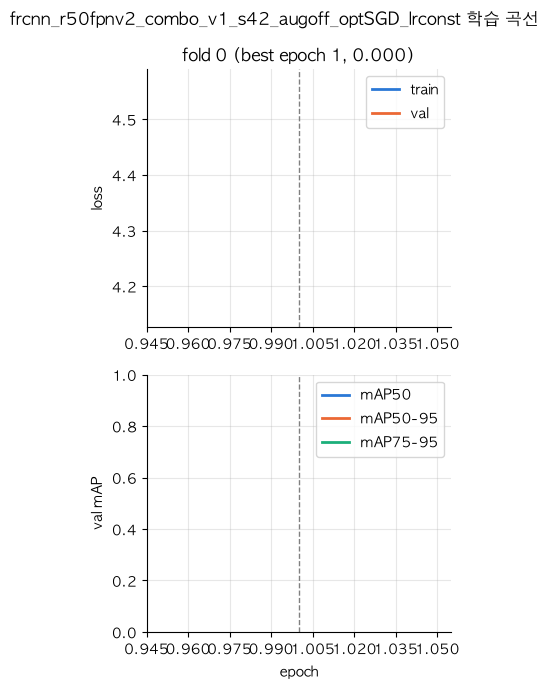

In [37]:
plot_curves(REPORT_CFG)

## 13. 혼동행렬

conf 0.001과 0.25로 그려 비교한다. 보기 좋은 쪽을 정하면 `CM_CONF`에 고정한다.
행 = 예측, 열 = 정답, 마지막 행·열은 배경(놓침·오검출). 축 이름은 category_id다.

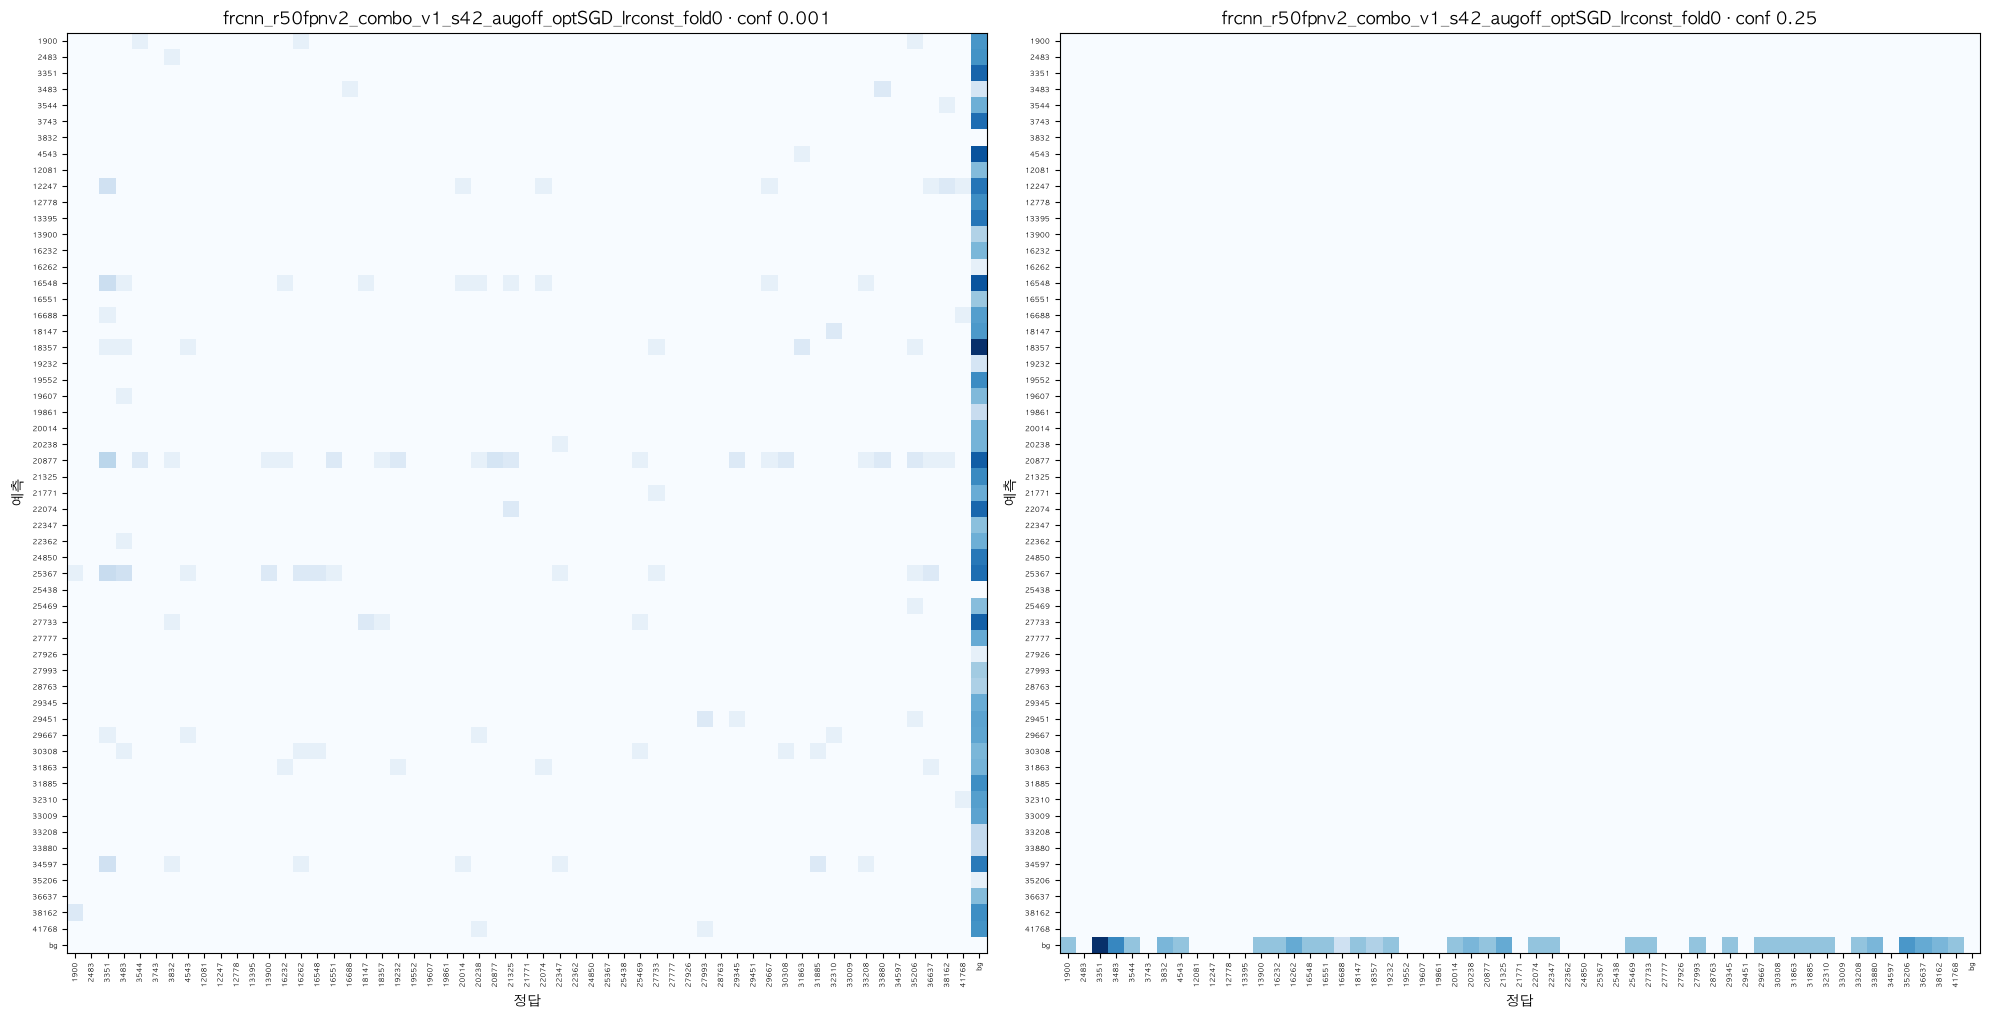

In [38]:
REPORT_FOLD = REPORT_CFG["folds"][0]


def load_val_pred(cfg: dict, fold: int) -> tuple[pd.DataFrame, pd.DataFrame, list[str]]:
    """evaluate_fold가 저장한 val 예측과 그 fold의 val 정답·사진 목록을 읽는다."""
    pred = pd.read_csv(results_dir(cfg) / f"{run_stem(cfg, fold)}_val_pred.csv")
    val_files = fold_files(fold, "val")
    return pred, LABELS[LABELS["file_name"].isin(val_files)], val_files


def plot_confusion(matrix: np.ndarray, title: str, ax: plt.Axes) -> None:
    """혼동행렬을 log 색으로 그린다. 대각선이 진할수록 좋다."""
    names = [*map(str, CLASS_MAP["category_id"]), "bg"]
    ax.imshow(np.log1p(matrix), cmap="Blues")
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=5)
    ax.set_yticks(range(len(names)), names, fontsize=5)
    ax.set_xlabel("정답")
    ax.set_ylabel("예측")
    ax.set_title(title)


val_pred, val_gt, val_files = load_val_pred(REPORT_CFG, REPORT_FOLD)
plot_dir = results_dir(REPORT_CFG) / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, cm_conf in zip(axes, [0.001, 0.25], strict=True):
    matrix = confusion_matrix(val_pred, val_gt, val_files, len(CLASS_MAP), cm_conf)
    plot_confusion(matrix, f"{run_stem(REPORT_CFG, REPORT_FOLD)} · conf {cm_conf:g}", ax)
fig.tight_layout()
fig.savefig(plot_dir / f"{run_stem(REPORT_CFG, REPORT_FOLD)}_confusion.png", dpi=120)
plt.show()

## 14. 실패 사례

고정 기준(신뢰도 0.5 이상, IoU 0.5 이상 짝)으로 val 예측을 정답과 짝짓고 세 가지 실패를 그린다.

- 놓침: 짝이 없는 정답 (초록 점선)
- 다른 약: 짝은 지었지만 약이 틀림 (빨강)
- 위치 어긋남: 약은 맞지만 IoU < 0.75 (주황). 주 지표 mAP75-95에서 점수를 받지 못한다.

정답은 초록 실선, 짝이 없는 예측(오검출)은 보라 점선이다. 실패가 많은 사진부터 그린다.

{'missed': 153} 오검출 0개


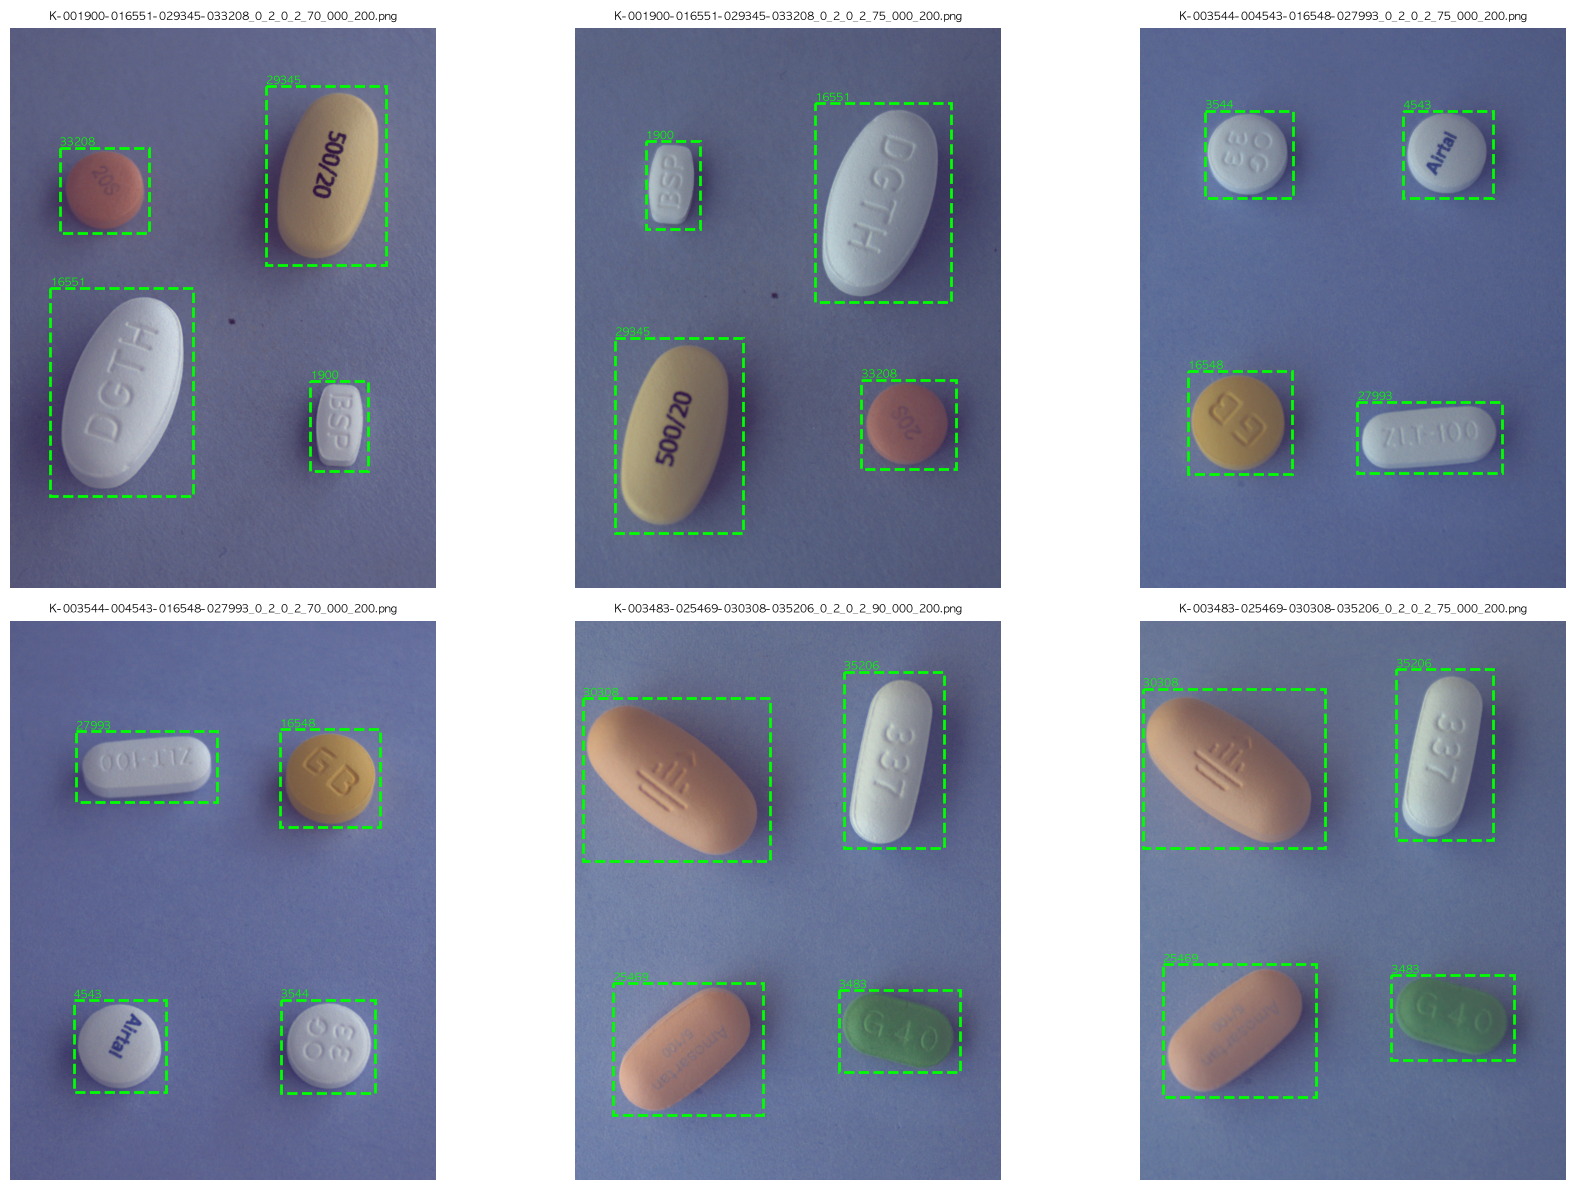

In [39]:
LOOSE_IOU = 0.75


def failure_table(pred: pd.DataFrame, gt: pd.DataFrame) -> pd.DataFrame:
    """정답마다 실패 종류(missed, wrong_class, loose_box, ok)와 짝지은 예측을 붙인 표."""
    pred = pred[pred["conf"] >= POINT_CONF]
    pairs = match_boxes(pred, gt).set_index("gt_row")
    table = gt.copy()
    table["pred_row"] = table.index.map(pairs["pred_row"])
    table["pred_category"] = table.index.map(pairs["pred_category"])
    table["iou"] = table.index.map(pairs["iou"])
    table["failure"] = np.select(
        [
            table["pred_row"].isna(),
            table["pred_category"] != table["category_id"],
            table["iou"] < LOOSE_IOU,
        ],
        ["missed", "wrong_class", "loose_box"],
        "ok",
    )
    return table


def plot_failures(
    pred: pd.DataFrame, gt: pd.DataFrame, n_images: int = 6, ncols: int = 3
) -> plt.Figure | None:
    """실패가 많은 사진 n_images장에 정답·예측 박스를 그린다."""
    table = failure_table(pred, gt)
    shown = pred[pred["conf"] >= POINT_CONF]
    unmatched = shown.drop(index=table["pred_row"].dropna().astype(int))
    n_fail = (table["failure"] != "ok").groupby(table["file_name"]).sum()
    n_fail = n_fail.add(unmatched["file_name"].value_counts(), fill_value=0)
    files = n_fail[n_fail > 0].sort_values(ascending=False).index[:n_images]
    if len(files) == 0:
        print("실패 사례가 없습니다.")
        return None
    print(table["failure"].value_counts().to_dict(), f"오검출 {len(unmatched)}개")
    nrows = math.ceil(len(files) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows), squeeze=False)
    colors = {"wrong_class": "red", "loose_box": "orange"}
    for ax, name in zip(axes.flat, files, strict=False):
        with Image.open(TRAIN_IMG_DIR / name) as img:
            ax.imshow(img.convert("RGB"))
        for _, row in table[table["file_name"] == name].iterrows():
            style = "--" if row["failure"] == "missed" else "-"
            ax.add_patch(
                Rectangle((row.x, row.y), row.w, row.h, fill=False, ec="lime", lw=2, ls=style)
            )
            ax.text(row.x, row.y - 5, str(row.category_id), color="lime", fontsize=8)
            if row["failure"] in colors:
                p = shown.loc[int(row["pred_row"])]
                color = colors[row["failure"]]
                ax.add_patch(Rectangle((p.x, p.y), p.w, p.h, fill=False, ec=color, lw=2))
                ax.text(
                    p.x,
                    p.y + p.h + 25,
                    f"{p.category_id} {p.conf:.2f} IoU {row.iou:.2f}",
                    color=color,
                    fontsize=8,
                )
        for _, p in unmatched[unmatched["file_name"] == name].iterrows():
            ax.add_patch(Rectangle((p.x, p.y), p.w, p.h, fill=False, ec="violet", lw=2, ls=":"))
            ax.text(
                p.x, p.y + p.h + 25, f"{p.category_id} {p.conf:.2f}", color="violet", fontsize=8
            )
        ax.set_title(name, fontsize=8)
        ax.axis("off")
    for ax in list(axes.flat)[len(files) :]:
        ax.axis("off")
    fig.tight_layout()
    return fig


fig = plot_failures(val_pred, val_gt)
if fig is not None:
    fig.savefig(plot_dir / f"{run_stem(REPORT_CFG, REPORT_FOLD)}_failures.png", dpi=100)
    plt.show()

## 15. test 예측과 제출 csv

한 fold의 `best.pt`로 test 842장을 예측해 제출 형식
`annotation_id, image_id, category_id, bbox_x, bbox_y, bbox_w, bbox_h, score`로 저장한다.
`category_id`는 원본 JSON id, 좌표는 원본 픽셀 xywh, `image_id`는 파일 이름의 숫자다.
행은 image_id 순, 같은 사진 안에서는 score가 높은 순이고 conf 0.001 미만은 버린다.

In [40]:
SUBMISSION_COLS = [
    "annotation_id",
    "image_id",
    "category_id",
    "bbox_x",
    "bbox_y",
    "bbox_w",
    "bbox_h",
    "score",
]


def to_submission(pred: pd.DataFrame) -> pd.DataFrame:
    """예측 표를 대회 제출 형식으로 바꾼다(models/evaluate.py의 to_submission과 같음)."""
    sub = pred.rename(
        columns={"x": "bbox_x", "y": "bbox_y", "w": "bbox_w", "h": "bbox_h", "conf": "score"}
    )
    sub["image_id"] = sub["file_name"].map(lambda name: int(Path(name).stem))
    sub = sub.sort_values(["image_id", "score"], ascending=[True, False], ignore_index=True)
    sub["annotation_id"] = sub.index + 1
    return sub[SUBMISSION_COLS]


def make_submission(cfg: dict, fold: int, device: str = DEVICE) -> tuple[pd.DataFrame, Path]:
    """fold의 best.pt로 test를 예측해 제출 csv를 저장하고 (제출 표, 경로)를 반환한다."""
    stem = run_stem(cfg, fold)
    weights = Path(cfg["runs_dir"]) / cfg["exp"] / stem / "weights" / "best.pt"
    model = load_model(weights, cfg, device)
    test_files = sorted(
        (p.name for p in TEST_IMG_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg"}),
        key=lambda name: int(Path(name).stem),
    )
    pred, _ = predict_images(model, TEST_IMG_DIR, test_files, device, cfg["eval_batch"], "test")
    pred = pred[pred["conf"] >= cfg["conf"]]
    out_dir = results_dir(cfg)
    pred.to_csv(out_dir / f"{stem}_test_pred.csv", index=False, encoding="utf-8")
    sub = to_submission(pred)
    out_path = out_dir / f"{stem}_submission_conf{cfg['conf']:g}.csv"
    sub.to_csv(out_path, index=False, encoding="utf-8")
    return sub, out_path


RUN_SUBMISSION = False
if RUN_SUBMISSION:
    sub, sub_path = make_submission(REPORT_CFG, REPORT_FOLD)
    print(f"사진 {sub['image_id'].nunique()}장, 박스 {len(sub)}개: {sub_path}")
    display(sub.head())